### Notebook 6b-2 — Second Case Study: Synthetic Tuberculosis Images with RoentGen-v2

> Generates synthetic chest X-rays with RoentGen-v2 (text-to-image latent diffusion model, used **zero-shot**) for the tuberculosis case study: 1,000 "tuberculosis" and 1,000 "normal" images. The model and the generation settings are those of Notebook 3b (pneumonia). RoentGen was trained on MIMIC-CXR reports, where tuberculosis is not a typical finding, so **the prompts are tested first (section 3) and the best wording is chosen by looking at the images**.

**Requirements in Kaggle**: GPU on, **Internet on**, a Kaggle Secret named `HF_TOKEN` (Add-ons → Secrets) with a Hugging Face token of an account that has accepted the conditions of `stanfordmimi/RoentGen-v2`; the token is read from the secret and is never written in the code. **Input to attach**: the output of Notebook 6a.

**Design decisions**

* **Zero-shot, no fine-tuning.** The model never sees Shenzhen images; a large domain gap is expected and is a limitation to state.
* **Prompt format** `<AGE> year old <SEX>. <IMPRESSION>`. The Shenzhen age and sex are not used, so they are sampled from a plain adult distribution (20-70 years, 50% male); this is a simplification.
* **The prompt choice is visual.** Images are **not** selected with any classifier score (it would pre-select easy cases). Only black, saturated or flat images are regenerated.
* **One seed per image**, so every image is reproducible; generation is resumable.
* **1,000 images per class** in the order of `index`, so dose subsets are the first *k* images.

**Saved** (`/kaggle/working`): `synthetic/roentgen/` (PNGs, plan and manifest) and `cache_tb_syn/roentgen.npy` + `roentgen_index.csv` (224 × 224, for the classifier).

### 1. Configuration and Loading

In [1]:
import os, time, json, math, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn.functional as F

SEED = 42
MODEL_ID = 'stanfordmimi/RoentGen-v2'
SIZE, STEPS, GUIDANCE = 512, 30, 4.0            # as in Notebook 3b
BATCH = 8
USE_DPM_SOLVER = True
DTYPE = torch.float16
N_SYN = {'pos': 1000, 'neg': 1000}
RUN_CLASSES = ['pos', 'neg']
MAX_ATTEMPTS, MIN_STD, MIN_MEAN, MAX_MEAN = 3, 12, 20, 235
MIN_AGE, MAX_AGE = 20, 70
RESUME_FROM = None

WORK = Path('/kaggle/working')
OUT_DIR, SYN_CACHE = WORK / 'synthetic' / 'roentgen', WORK / 'cache_tb_syn'
for sub in ('tuberculosis', 'normal'): (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)
SYN_CACHE.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
assert DEVICE == 'cuda', 'Enable a GPU accelerator (Settings -> Accelerator)'
print('GPU:', torch.cuda.get_device_name(0))

# --- Hugging Face token from Kaggle Secrets (never hard-code it) ---
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret('HF_TOKEN')
except Exception:
    HF_TOKEN = os.environ.get('HF_TOKEN')
assert HF_TOKEN, 'HF_TOKEN not found: add it in Add-ons -> Secrets and attach it to this notebook'

# --- Locate the cache written by Notebook 6a (used only to show real images for comparison) ---
CACHE_TB = None
for cur, dirs, files in os.walk('/kaggle/input'):
    if 'train.npy' in files and 'train_index.csv' in files: CACHE_TB = Path(cur); break
assert CACHE_TB, 'cache_tb not found under /kaggle/input: attach the output of Notebook 6a via + Add Input'
Xtr = np.load(CACHE_TB / 'train.npy'); Itr = pd.read_csv(CACHE_TB / 'train_index.csv'); assert set(Itr['source']) == {'shenzhen'}
print('CACHE_TB =', CACHE_TB, '|', {int(l): int((Itr.label == l).sum()) for l in (0, 1)}, '(real training images, label: count)')

GPU: Tesla T4
CACHE_TB = /kaggle/input/notebooks/anamatemalas/06a-tb-data-preparation/cache_tb | {0: 195, 1: 201} (real training images, label: count)


### 2. Load RoentGen-v2

Loaded in half precision without the Stable Diffusion safety checker (it can blank out medical images). Run the install cell once per session.

In [2]:
if RESUME_FROM:
    import shutil
    cands = [p for p in Path('/kaggle/input').rglob('roentgen') if p.is_dir()]
    info = {str(p): len(list(p.rglob('*.png'))) for p in cands}
    print('roentgen folders found in /kaggle/input and their PNG count:', info)
    assert info and max(info.values()) > 0, ('no previous roentgen images found in the inputs: '
        'check + Add Input (03b output) and which version of that notebook is being used')
    best = Path(max(info, key=info.get))
    n_copied = 0
    for f in best.rglob('*'):
        if f.is_file() and f.name != 'roentgen_plan.csv' and not f.name.startswith('roentgen_manifest'):
            dst = OUT_DIR / f.relative_to(best); dst.parent.mkdir(parents=True, exist_ok=True)
            if not dst.exists():
                shutil.copy2(f, dst); n_copied += 1
    print(f'Resumed from {best}: {n_copied:,} files copied')
else:
    print('Fresh run (RESUME_FROM is None)')

Fresh run (RESUME_FROM is None)


In [3]:
%pip install -q -U diffusers transformers accelerate
%pip uninstall -y -q torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 11.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [4]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=DTYPE, safety_checker=None,
                                               requires_safety_checker=False, token=HF_TOKEN)
pipe = pipe.to(DEVICE); pipe.enable_attention_slicing(); pipe.set_progress_bar_config(disable=True)
if USE_DPM_SOLVER:
    from diffusers import DPMSolverMultistepScheduler
    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
print('RoentGen-v2 loaded | scheduler:', type(pipe.scheduler).__name__,
      '| prediction_type:', getattr(pipe.scheduler.config, 'prediction_type', None))

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

RoentGen-v2 loaded | scheduler: DPMSolverMultistepScheduler | prediction_type: epsilon


### 3. Prompt Test (look at the images before the full run)

RoentGen was trained on MIMIC-CXR impressions. Tuberculosis is rare there, so the wording matters. For each candidate wording, 8 images are generated with the **same 8 seeds**, and shown with real Shenzhen tuberculosis and normal images. Choose the wordings whose images look closest to the real tuberculosis ones (upper-lobe opacities, cavities, fibrosis) and write them in `POS_IMPRESSIONS` in the next section. This takes a few minutes and uses no classifier.

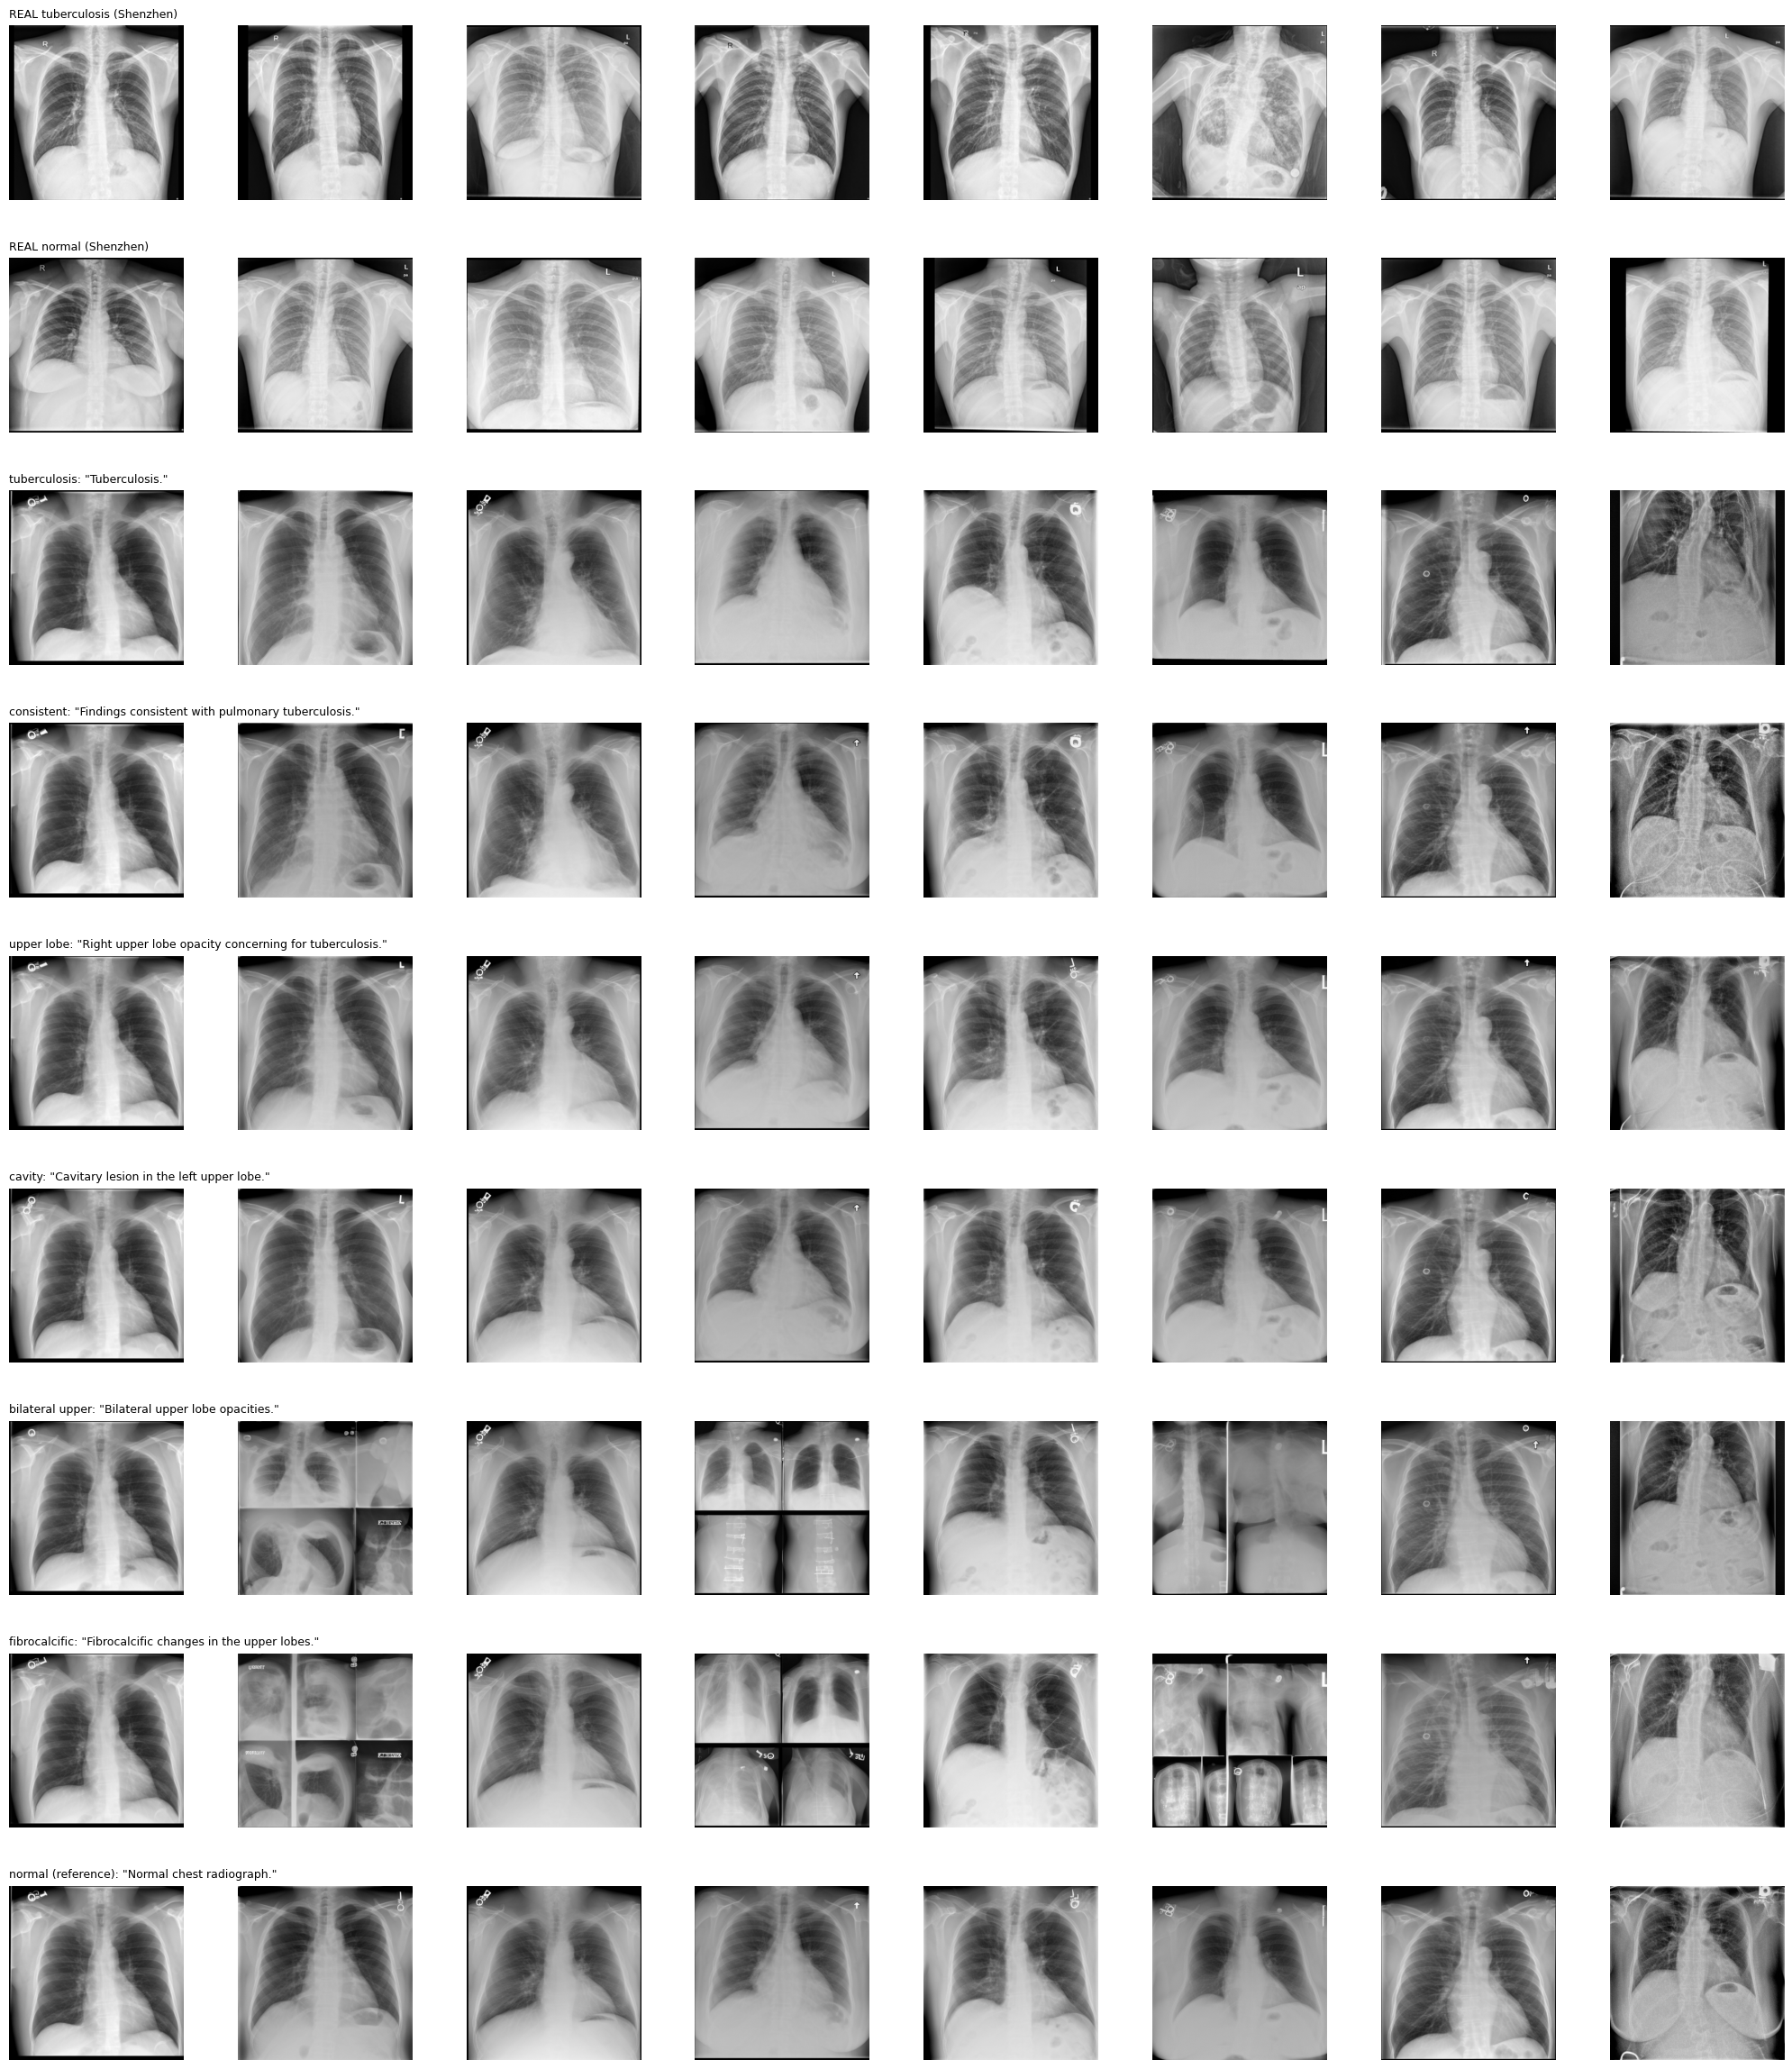

In [5]:
PILOT = {'tuberculosis': 'Tuberculosis.', 'consistent': 'Findings consistent with pulmonary tuberculosis.',
         'upper lobe': 'Right upper lobe opacity concerning for tuberculosis.', 'cavity': 'Cavitary lesion in the left upper lobe.',
         'bilateral upper': 'Bilateral upper lobe opacities.', 'fibrocalcific': 'Fibrocalcific changes in the upper lobes.',
         'normal (reference)': 'Normal chest radiograph.'}
PILOT_AGE_SEX = ['45 year old male.', '30 year old female.', '55 year old male.', '25 year old female.', '60 year old male.', '40 year old female.', '35 year old male.', '50 year old female.']
@torch.no_grad()
def pilot_images(imp):
    gens = [torch.Generator(device=DEVICE).manual_seed(900_000 + k) for k in range(8)]
    return pipe([f'{a} {imp}' for a in PILOT_AGE_SEX], num_inference_steps=STEPS, guidance_scale=GUIDANCE, height=SIZE, width=SIZE, generator=gens).images
rs = np.random.RandomState(SEED); real_tb = Xtr[rs.choice(np.where(Itr.label.values == 1)[0], 8, replace=False)]; real_nm = Xtr[rs.choice(np.where(Itr.label.values == 0)[0], 8, replace=False)]
rows = list(PILOT.items()); fig, ax = plt.subplots(len(rows) + 2, 8, figsize=(20, 2.6 * (len(rows) + 2)))
for k in range(8):
    ax[0, k].imshow(real_tb[k], cmap='gray'); ax[1, k].imshow(real_nm[k], cmap='gray')
ax[0, 0].set_title('REAL tuberculosis (Shenzhen)', fontsize=9, loc='left'); ax[1, 0].set_title('REAL normal (Shenzhen)', fontsize=9, loc='left')
for r, (name, imp) in enumerate(rows):
    ims = pilot_images(imp)
    for k, im in enumerate(ims): ax[r + 2, k].imshow(im.convert('L'), cmap='gray')
    ax[r + 2, 0].set_title(f'{name}: "{imp}"', fontsize=9, loc='left')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.savefig(WORK / 'fig_prompt_test.png', dpi=110); plt.show()

### 4. Prompt Plan

Builds the table of all 2,000 images (prompt, age, sex, seed, output path) **before** generating and saves it as `roentgen_plan.csv`. Edit `POS_IMPRESSIONS` after looking at the figure above; the default list contains all the pilot wordings that describe tuberculosis.

In [6]:
POS_IMPRESSIONS = ['Tuberculosis.', 'Findings consistent with pulmonary tuberculosis.', 'Right upper lobe opacity concerning for tuberculosis.',
                   'Cavitary lesion in the left upper lobe.', 'Bilateral upper lobe opacities.', 'Fibrocalcific changes in the upper lobes.']      # <- edit after the prompt test
NEG_IMPRESSIONS = ['Normal chest radiograph.', 'No acute cardiopulmonary abnormality.', 'No acute cardiopulmonary process.']

rng = np.random.default_rng(SEED); rows = []
for cls, label, base_seed, folder in [('pos', 1, 300_000, 'tuberculosis'), ('neg', 0, 400_000, 'normal')]:
    impressions = POS_IMPRESSIONS if label else NEG_IMPRESSIONS
    for i in range(N_SYN[cls]):
        age = int(rng.integers(MIN_AGE, MAX_AGE + 1)); sex_txt = 'male' if rng.random() < 0.5 else 'female'
        imp = impressions[int(rng.integers(len(impressions)))]; fn = f'roentgen_{cls}_{i:05d}.png'
        rows.append({'image': fn, 'path': str(OUT_DIR / folder / fn), 'cls': cls, 'label': label, 'index': i, 'gen_seed': base_seed + i,
                     'age': age, 'sex': sex_txt, 'impression': imp, 'prompt': f'{age} year old {sex_txt}. {imp}'})
plan = pd.DataFrame(rows); plan.to_csv(OUT_DIR / 'roentgen_plan.csv', index=False)
print(plan.groupby('cls').agg(n=('image', 'size'), age_mean=('age', 'mean'), male_pct=('sex', lambda s: 100 * (s == 'male').mean())).round(1))
print('\nExample prompts:'); print(plan.groupby('cls').head(3)[['cls', 'prompt', 'gen_seed']].to_string(index=False))

        n  age_mean  male_pct
cls                          
neg  1000      44.0      51.5
pos  1000      45.3      50.0

Example prompts:
cls                                                        prompt  gen_seed
pos             24 year old male. Bilateral upper lobe opacities.    300000
pos 42 year old female. Fibrocalcific changes in the upper lobes.    300001
pos                             30 year old female. Tuberculosis.    300002
neg           36 year old male. No acute cardiopulmonary process.    400000
neg         60 year old female. No acute cardiopulmonary process.    400001
neg                  29 year old female. Normal chest radiograph.    400002


### 5. Generation Functions and Timing Test

One seeded generator per image, 8-bit grayscale, and regeneration (new seed, up to `MAX_ATTEMPTS`) of any black, saturated or flat image. The timing test generates and **keeps** the first batch and extrapolates the total time: read it before the full run. If most images come out black, switch `DTYPE` to `torch.float32`.

5.7 s/image  ->  about 3.2 h for 2,000 images
Degenerate images in this batch: 0 | extra attempts: 0


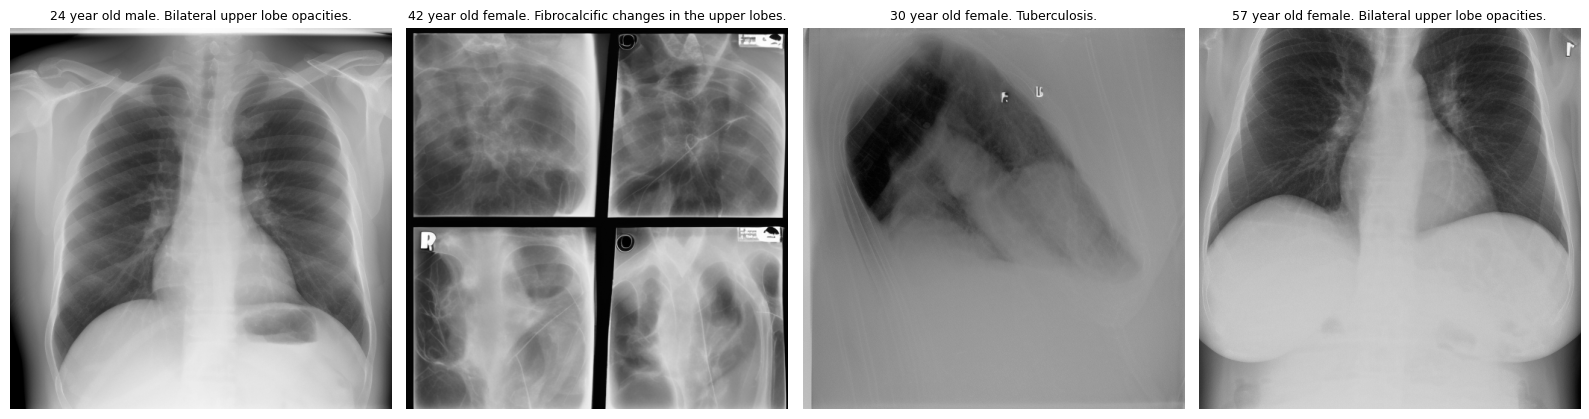

In [7]:
LOG = OUT_DIR / 'roentgen_log.jsonl'

def is_degenerate(a):
    return a.std() < MIN_STD or a.mean() < MIN_MEAN or a.mean() > MAX_MEAN

@torch.no_grad()
def run_batch(rows):
    results, pending = {}, list(range(len(rows)))
    for attempt in range(MAX_ATTEMPTS):
        if not pending:
            break
        sub = rows.iloc[pending]
        gens = [torch.Generator(device=DEVICE).manual_seed(int(s) + attempt * 10_000_000) for s in sub['gen_seed']]
        imgs = pipe(list(sub['prompt']), num_inference_steps=STEPS, guidance_scale=GUIDANCE,
                    height=SIZE, width=SIZE, generator=gens).images
        still = []
        for j, im in zip(pending, imgs):
            a = np.asarray(im.convert('L'), dtype=np.uint8)
            if is_degenerate(a) and attempt < MAX_ATTEMPTS - 1:
                still.append(j)
            else:
                results[j] = (a, attempt + 1, bool(is_degenerate(a)))
        pending = still
    return results

def process(batch):
    res = run_batch(batch)
    with open(LOG, 'a') as f:
        for j, (a, att, bad) in res.items():
            r = batch.iloc[j]
            Image.fromarray(a, 'L').save(r['path'])
            f.write(json.dumps({'image': r['image'], 'attempts': att, 'degenerate': bad}) + '\n')
    return res

first = plan[plan.cls == RUN_CLASSES[0]].iloc[:BATCH]
first = first[~first.path.map(os.path.exists)]
if len(first):
    t0 = time.time(); res = process(first)
    if DEVICE == 'cuda': torch.cuda.synchronize()
    per_img = (time.time() - t0) / len(first)
    print(f'{per_img:.1f} s/image  ->  about {sum(N_SYN[c] for c in RUN_CLASSES) * per_img / 3600:.1f} h for {sum(N_SYN[c] for c in RUN_CLASSES):,} images')
    print('Degenerate images in this batch:', sum(v[2] for v in res.values()), '| extra attempts:', sum(v[1] - 1 for v in res.values()))
fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
for a_, (_, r) in zip(ax, plan[plan.cls == RUN_CLASSES[0]].iloc[:4].iterrows()):
    a_.imshow(Image.open(r['path']), cmap='gray'); a_.set_title(r['prompt'], fontsize=9); a_.axis('off')
plt.tight_layout(); plt.show()

### 6. Full Generation

Resumable: it only generates images whose PNG does not exist yet, so after an interruption it can be run again.

In [8]:
todo = plan[plan.cls.isin(RUN_CLASSES) & ~plan.path.map(os.path.exists)]
print(f'{len(todo):,} images to generate ({int(plan.path.map(os.path.exists).sum()):,} already on disk)')
t0, done = time.time(), 0
for i in range(0, len(todo), BATCH):
    batch = todo.iloc[i:i + BATCH]
    process(batch); done += len(batch)
    if (i // BATCH) % 25 == 0 or done == len(todo):
        el = time.time() - t0
        print(f'{done:,}/{len(todo):,} | {el / 60:.0f} min elapsed | about {(len(todo) - done) * el / done / 60:.0f} min left')

1,992 images to generate (8 already on disk)
8/1,992 | 1 min elapsed | about 179 min left
208/1,992 | 19 min elapsed | about 164 min left
408/1,992 | 38 min elapsed | about 146 min left
608/1,992 | 56 min elapsed | about 128 min left
808/1,992 | 74 min elapsed | about 109 min left
1,008/1,992 | 93 min elapsed | about 91 min left
1,208/1,992 | 111 min elapsed | about 72 min left
1,408/1,992 | 130 min elapsed | about 54 min left
1,608/1,992 | 148 min elapsed | about 35 min left
1,808/1,992 | 167 min elapsed | about 17 min left
1,992/1,992 | 184 min elapsed | about 0 min left


### 7. Manifest

In [9]:
log = (pd.read_json(LOG, lines=True).drop_duplicates('image', keep='last')
       if LOG.exists() else pd.DataFrame(columns=['image', 'attempts', 'degenerate']))
man = plan.merge(log, on='image', how='left')
man = man[man.path.map(os.path.exists) & man.cls.isin(RUN_CLASSES)].copy()
man['source'], man['generator'], man['img_size'] = 'synthetic', 'roentgen_v2', SIZE
man['attempts'] = man['attempts'].fillna(1).astype(int); man['degenerate'] = man['degenerate'].fillna(False).astype(bool)
tag = '' if set(RUN_CLASSES) == {'pos', 'neg'} else '_' + '_'.join(RUN_CLASSES)     # per-class manifest if run separately
man.to_csv(OUT_DIR / f'roentgen_manifest{tag}.csv', index=False)

print(f'{len(man):,} images in the manifest (planned {int(plan.cls.isin(RUN_CLASSES).sum()):,})')
print(man.groupby('label').size().rename('images'))
print('\nDegenerate after all attempts:', int(man.degenerate.sum()), '| needed a retry:', int((man.attempts > 1).sum()))

2,000 images in the manifest (planned 2,000)
label
0    1000
1    1000
Name: images, dtype: int64

Degenerate after all attempts: 0 | needed a retry: 0


### 8. Visual Check and Intensity Statistics

First 8 synthetic images of each class (with their prompts) above 8 real Shenzhen training images of the same class, and the mean / contrast of both at 224 × 224.

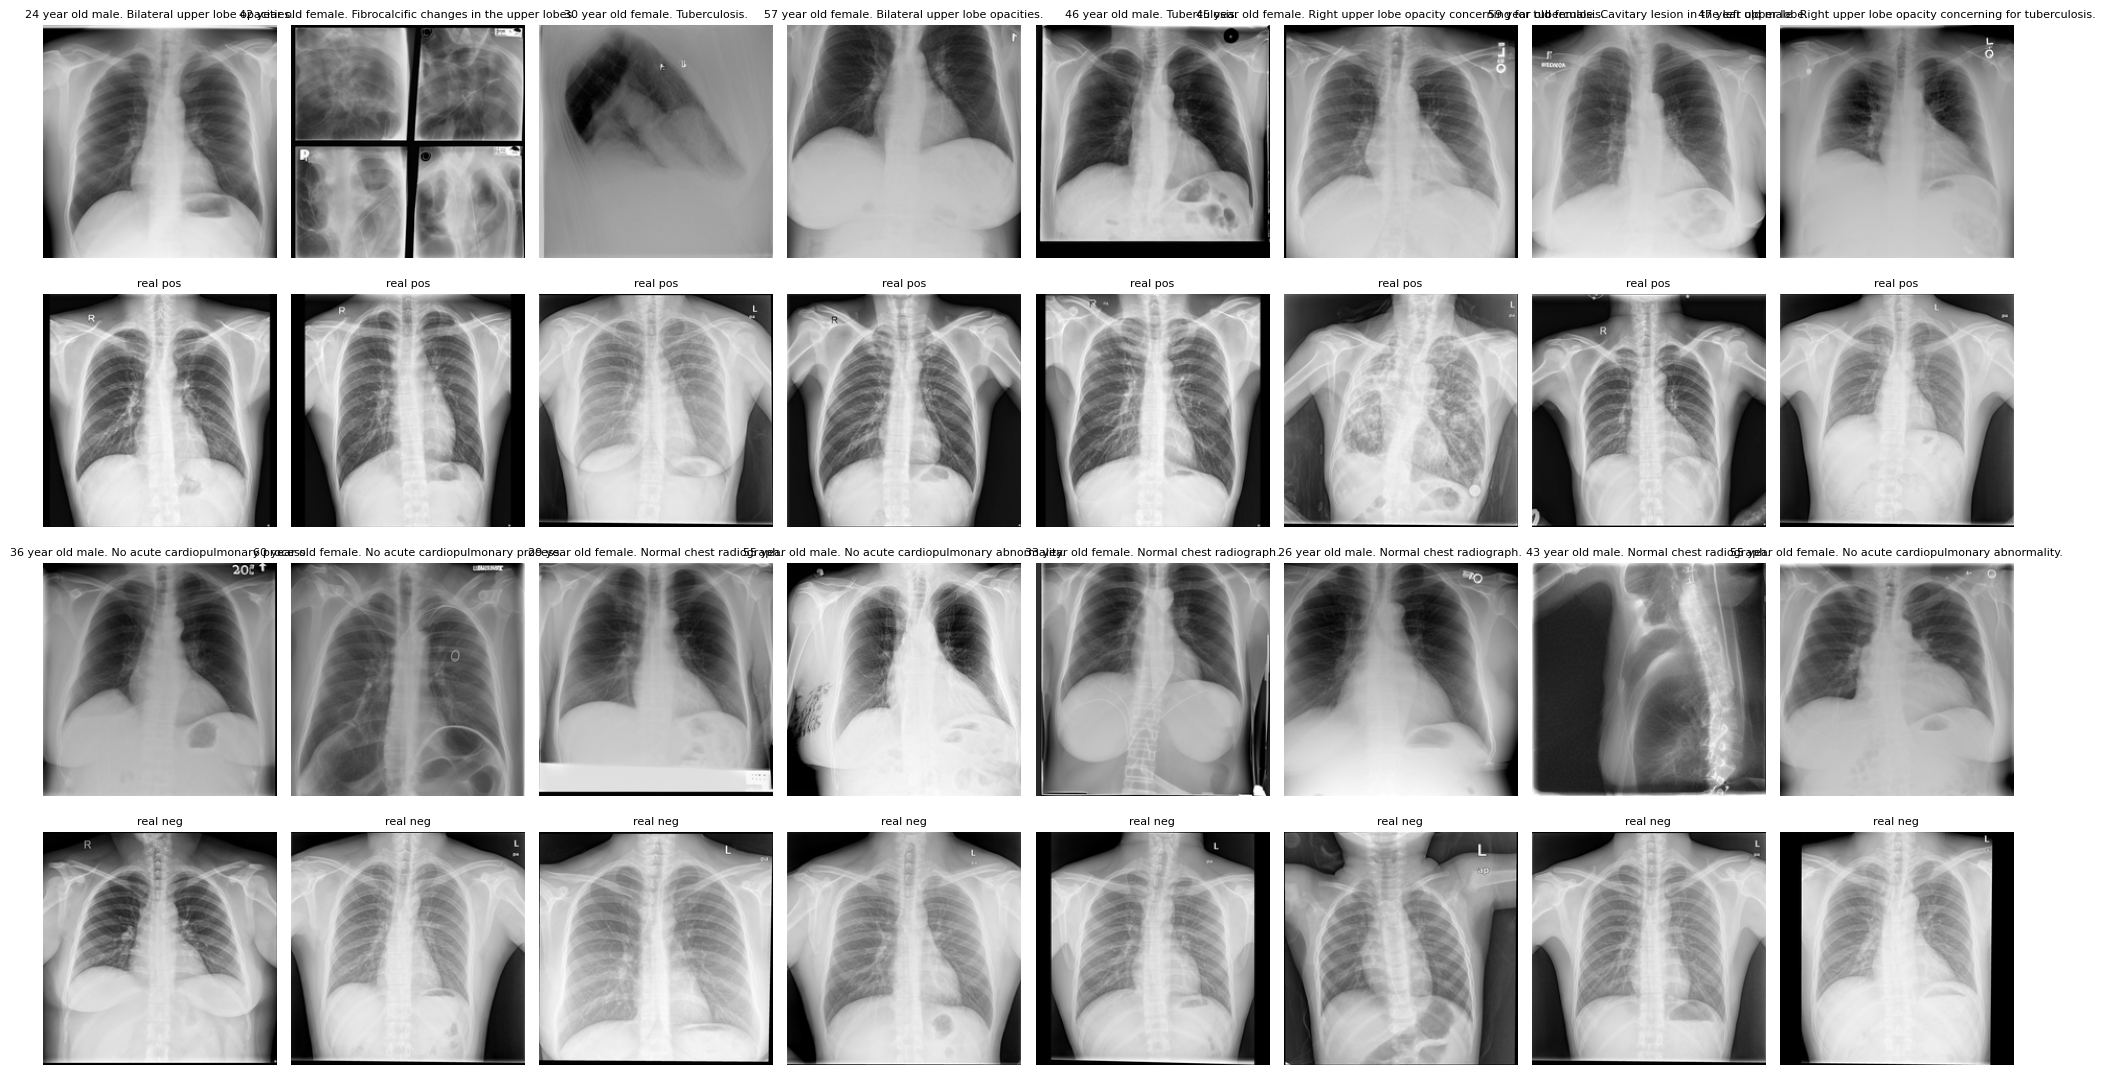

               mean intensity  contrast (within-image std)  \
pos real           142.300003                    72.099998   
    synthetic      133.500000                    51.000000   
neg real           153.500000                    69.099998   
    synthetic      134.199997                    54.099998   

               spread of image means  
pos real                        12.1  
    synthetic                   11.0  
neg real                        14.9  
    synthetic                   10.7  


In [10]:
to224 = lambda p: np.asarray(Image.open(p).convert('L').resize((224, 224), Image.Resampling.LANCZOS), dtype=np.uint8)
CLASSES = [(c, l) for c, l in [('pos', 1), ('neg', 0)] if (man.cls == c).any()]
fig, ax = plt.subplots(2 * len(CLASSES), 8, figsize=(20, 5.5 * len(CLASSES)), squeeze=False); rs = np.random.RandomState(SEED)
for r, (cls, lab) in enumerate(CLASSES):
    syn = man[man.cls == cls].head(8); real = Xtr[rs.choice(np.where(Itr.label.values == lab)[0], 8, replace=False)]
    for k, ((_, s), a) in enumerate(zip(syn.iterrows(), real)):
        ax[2 * r, k].imshow(to224(s['path']), cmap='gray'); ax[2 * r, k].set_title(s['prompt'], fontsize=8)
        ax[2 * r + 1, k].imshow(a, cmap='gray'); ax[2 * r + 1, k].set_title(f'real {cls}', fontsize=8)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.savefig(WORK / 'fig_samples.png', dpi=110); plt.show()
stats = {}
for cls, lab in CLASSES:
    syn = np.stack([to224(p) for p in man[man.cls == cls].sample(min(200, int((man.cls == cls).sum())), random_state=SEED)['path']]).astype(np.float32)
    real = Xtr[Itr.label.values == lab].astype(np.float32)
    for name, a in (('real', real), ('synthetic', syn)):
        stats[(cls, name)] = {'mean intensity': a.mean(), 'contrast (within-image std)': a.std(axis=(1, 2)).mean(), 'spread of image means': a.mean(axis=(1, 2)).std()}
print(pd.DataFrame(stats).T.round(1))

### 9. Export for the Classifier

Images are resized from 512 to 224 pixels with Lanczos resampling (as in the pneumonia pipeline). Degenerate images are left out. The index is sorted by class (tuberculosis first) and `index`.

In [11]:
ex = man[~man['degenerate']].sort_values(['label', 'index'], ascending=[False, True]).reset_index(drop=True)
X224 = np.stack([to224(p) for p in ex['path']])
np.save(SYN_CACHE / 'roentgen.npy', X224); ex.drop(columns=['path']).to_csv(SYN_CACHE / 'roentgen_index.csv', index=False)
total = sum(f.stat().st_size for f in WORK.rglob('*') if f.is_file()) / 1e6
print(X224.shape, X224.dtype, f'| {len(man) - len(ex)} degenerate images left out | output: {total:.0f} MB'); print(sorted(p.name for p in SYN_CACHE.iterdir()))

(2000, 224, 224) uint8 | 0 degenerate images left out | output: 361 MB
['roentgen.npy', 'roentgen_index.csv']
